# Portalegre --> distrito 13

In [ ]:
# Reiniciar o programa
#import os
#os.kill(os.getpid(),9)

In [88]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
import pickle 
from tqdm import tqdm
import numpy as np
from sklearn.metrics import mean_squared_error

df_13 = pd.read_csv('df_13_d.csv')
df_13_y = pd.read_csv('df_13_y_d.csv')

df_13['ID'] = [i for i in range(len(df_13))]
df_13_y['ID'] = [i for i in range(len(df_13_y))]

# Coluna = 'Unnamed: 0' --> corresponde aos id reais!! <-- IMP

In [89]:
#df_13

In [90]:
#df_13_y

# Pre-processamento 

### Colunas: 
- built_in
- amenities
- energetic_efficiency

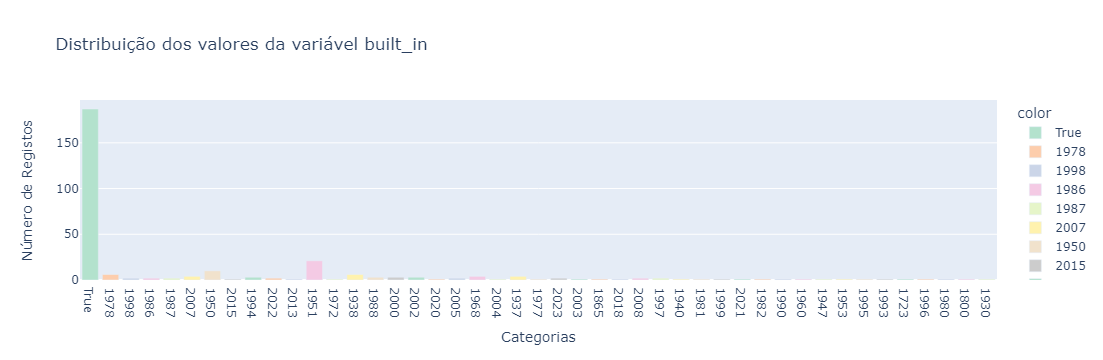

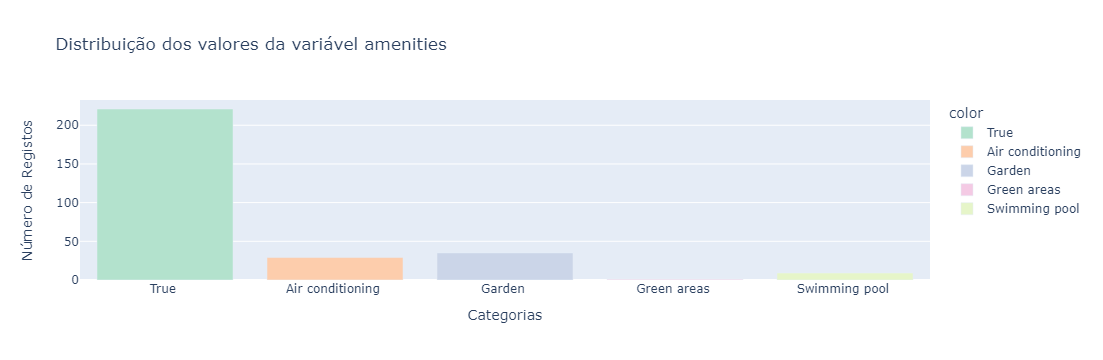

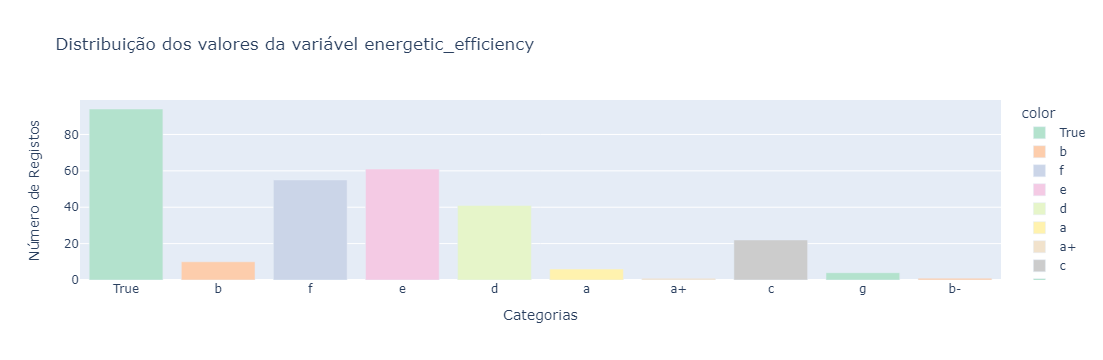

In [91]:
# Variação dos dados 
import plotly.express as px
col = ['built_in', 'amenities','energetic_efficiency']

for nome in col: 
    output = []
    names = df_13[nome].unique()
    for i in df_13[nome].unique():
        bt2 = df_13[nome].value_counts()[i]
        output.append(bt2)
    fig = px.bar(df_13, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos valores da variável {nome}')
    fig.update_xaxes(title_text='Categorias')
    fig.update_yaxes(title_text='Número de Registos')
    fig.show()

### --> Eficiência Energética

In [92]:
from sklearn.neighbors import KNeighborsClassifier
# Cluster para ver as casas mais parecidas, para depois asoociar um valor aos imóveis que não têm eficiencia energética

# Obter ID onde energetic_efficiency == 'True' e ou != 'True'
ids_true = list(df_13.loc[df_13['energetic_efficiency'] == 'True', 'ID']) # O que vão ser previstos 
ids_a_mais = list(df_13.loc[df_13['energetic_efficiency'] == 'a+', 'ID']) # como só havia 1 sample replicar 2x
ids_b_menos = list(df_13.loc[df_13['energetic_efficiency'] == 'b-', 'ID']) # como só havia 1 sample replicar 2x
ids_outros = list(df_13.loc[df_13['energetic_efficiency'] != 'True', 'ID'])

# Como há elementos só com 1 elemento meter mais 2 --> replicar
ids_outros.append(ids_a_mais[0])
ids_outros.append(ids_a_mais[0])
ids_outros.append(ids_b_menos[0])
ids_outros.append(ids_b_menos[0])

# Dados 
teste = df_13.loc[ids_true,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
#teste_y = df_13.loc[ids_true,['energetic_efficiency']]
treino = df_13.loc[ids_outros,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
treino_y = df_13.loc[ids_outros,['energetic_efficiency']]

# Comparação --> X_train_13[['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
def KNN(k, teste, treino, treino_y):
    knn =  KNeighborsClassifier(n_neighbors=k)
    knn.fit(treino, treino_y)
    y_pred = knn.predict(teste)
    return y_pred
l_ee = KNN(3, teste, treino, treino_y)

# Substituir os True

def sub_ee(ids_true, l_ee, df, col):
    for i in range(len(ids_true)): 
        df.loc[df['ID'] == ids_true[i], col] = l_ee[i]
    return df
df_13 = sub_ee(ids_true, l_ee, df_13, 'energetic_efficiency')


ee = df_13.loc[:, ['energetic_efficiency']]

def substituir_energetic_efficiency(X):
    X = X.replace('a+', 1)
    X = X.replace('a', 2)
    X = X.replace('b', 3)
    X = X.replace('b-', 4)
    X = X.replace('c', 5)
    X = X.replace('d', 6)
    X = X.replace('e', 7)
    X = X.replace('f', 8)
    X = X.replace('g', 9)
    
    return X
ee = substituir_energetic_efficiency(ee)

# normalizar valores 
def norm_ee(df1): 
    
    df1['energetic_efficiency'] = df1['energetic_efficiency'] /df1['energetic_efficiency'].abs().max()
    return df1
ee = norm_ee(ee)

df_13['energetic_efficiency'] = ee

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



### --> Amenities

In [93]:
aa = df_13.loc[:, ['amenities']]

def substituir_amenities(X):
    X = X.replace('True ', 1)
    X = X.replace('Air conditioning ', 2)
    X = X.replace('Garden ', 3)
    X = X.replace('Green areas ', 3)
    X = X.replace('Swimming pool ', 4)
    
    return X
aa = substituir_amenities(aa)

# normalizar valores 
def norm_amenities(df1): 
    
    df1['amenities'] = df1['amenities'] /11
    return df1
aa = norm_amenities(aa)

df_13['amenities'] = aa

### --> built_in

In [94]:
id_true = list(df_13.loc[df_13['built_in'] == 'True', 'ID'])
id_outros = list(df_13.loc[df_13['built_in'] != 'True', 'ID'])

# Obter anos que têm menos de 2 samples 

def menos_2(df, nome): 
    l = []
    for i in df[nome].unique():
        bt2 = df[nome].value_counts()[i]
        if bt2 < 3: 
            l.append(i) 
    return l
lista_data13 = menos_2(df_13, 'built_in')

def replicação_menos2(df, lista_data, id_outros):
    for ano in lista_data: 
        id_ano = list(df.loc[df['built_in'] == ano, 'ID'])
        for i in range(len(id_ano)):
            id_outros.append(id_ano[i])
            id_outros.append(id_ano[i])
    return id_outros

id_outros = replicação_menos2(df_13, lista_data13, id_outros)

# Dados 
# criar dataset com price

d_b =  df_13.loc[:,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
d_b_2 = df_13_y.loc[:,['Price_norm']]
#d_b = pd.concat([d_b_1, d_b_2])
d_b = d_b.join(d_b_2)


teste_b = d_b.loc[id_true,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
#teste_y = df_13.loc[ids_true,['built_in']]
treino_b = d_b.loc[id_outros,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
treino_b_y = df_13.loc[id_outros,['built_in']]

# KNN
l_b_i = KNN(3, teste_b, treino_b, treino_b_y)

# Substituir
df_13 = sub_ee(id_true, l_b_i, df_13, 'built_in')

b_i = df_13.loc[:, ['built_in']]
b_i['built_in'] = b_i['built_in'].astype(int)

# normalizar valores 
def norm_b_i(df1): 
    
    df1['built_in'] = df1['built_in'] /2024
    return df1
b_i = norm_b_i(b_i)

df_13['built_in'] = b_i

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



In [95]:
df_13

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,0,0.957016,0.142857,0.090909,0.16,0.16,0.777778,0.142857,0.692057,-0.070647,0
1,4,0.977273,0.142857,0.090909,0.04,0.04,0.777778,0.428571,0.692057,-0.070647,1
2,19,0.992095,0.428571,0.090909,0.38,0.34,0.333333,0.571429,0.692057,-0.070647,2
3,39,0.990119,0.357143,0.090909,0.24,0.24,0.888889,0.571429,0.691865,-0.069930,3
4,44,0.982213,0.285714,0.090909,0.18,0.12,0.888889,0.571429,0.690599,-0.068934,4
...,...,...,...,...,...,...,...,...,...,...,...
290,4403,0.986660,0.142857,0.090909,0.08,0.06,0.222222,0.285714,0.692057,-0.070647,290
291,4417,0.986660,0.214286,0.090909,0.12,0.12,0.888889,0.142857,0.691360,-0.067698,291
292,4448,0.953557,0.142857,0.090909,0.10,0.08,0.666667,1.000000,0.690599,-0.068934,292
293,4465,0.961957,0.785714,0.181818,0.10,0.74,0.555556,0.142857,0.690848,-0.069038,293


# Modelo

In [96]:

# Dividir em treino e teste

X_train_13, X_test_13, y_train_13, y_test_13 = train_test_split(df_13, df_13_y, test_size=0.15, random_state=42)
X_train_13

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
226,3399,0.968379,0.214286,0.090909,0.08,0.08,0.777778,1.000000,0.690786,-0.069041,226
25,423,0.995553,0.214286,0.181818,0.12,0.12,0.333333,0.285714,0.691325,-0.069359,25
77,977,0.968379,0.214286,0.272727,0.12,0.10,0.666667,1.000000,0.692064,-0.070639,77
6,99,0.957016,0.357143,0.181818,0.22,0.22,0.777778,0.428571,0.691887,-0.070644,6
175,2614,0.986660,0.214286,0.090909,0.10,0.10,0.888889,0.142857,0.691627,-0.070151,175
...,...,...,...,...,...,...,...,...,...,...,...
188,2768,0.977273,0.214286,0.090909,0.26,0.26,0.888889,0.285714,0.691361,-0.069431,188
71,919,0.953557,0.071429,0.090909,0.30,0.30,0.666667,1.000000,0.692057,-0.070647,71
106,1471,0.957510,0.357143,0.090909,0.22,0.14,0.777778,0.142857,0.692057,-0.070647,106
270,4177,0.986166,0.285714,0.090909,0.18,0.18,0.666667,0.571429,0.691292,-0.069337,270


In [97]:
X_train = X_train_13[['tipology', 'amenities', 'built_in','energetic_efficiency', 'house_type']]
X_test = X_test_13[[ 'tipology', 'amenities', 'built_in', 'energetic_efficiency', 'house_type']]
y_train = y_train_13[['Price_norm']]
y_test = y_test_13[['Price_norm']]

# MLPRegressor

### Melhor segundo GridSearchCV

In [98]:
# Melhor segundo GridSearchCV --< colab
"""
regr = MLPRegressor(hidden_layer_sizes=(170,), activation='relu',  solver='lbfgs',alpha=0.001, learning_rate= 'adaptive', learning_rate_init = 0.0001,  tol = 0.0001, max_iter=800).fit(X_train, y_train)
y_pred = regr.predict(X_test)
y_pred = [abs(x) for x in y_pred]
print(y_pred)
print(mean_squared_error(y_pred,y_test))
print(regr.score(X_test, y_test))


### Guardar o modelo

import pickle

with open('modelo_dist13.pkl', 'wb') as file:
    pickle.dump(regr, file)
"""

[0.04599630117307945, 0.009905054379897277, 0.03549164167102626, 0.0059052296333310505, 0.006720751679915374, 0.0049464952108403395, 0.00025943607896611754, 0.009878299881905698, 0.016042096561087044, 0.030403467920763094, 0.0064867567482128395, 0.0211324696755662, 0.09743975162797094, 0.02515602398262845, 0.005929292195984161, 0.004020429957410911, 0.013778401408453822, 0.018554701463269915, 0.014483065895874545, 0.005187000756624017, 0.004692368997265357, 0.005187000756624017, 0.03464021471645338, 0.00546458955379889, 0.007820385433585975, 0.028717567447041778, 0.006720751679915374, 0.03425203841987321, 0.012590904690063204, 0.002240020090818769, 0.006668520188006563, 0.001329828576258821, 0.03418677767720771, 0.016839836525064406, 0.015754590762643808, 0.009555067754685148, 0.010870161220154575, 0.006602603801418459, 0.021235361461449907, 0.015629312654088897, 0.013710240333086113, 0.048012447632190355, 0.00978864269584978, 0.0015167791597803454, 0.009788642695849795]
0.000231381227

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1625: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



In [80]:
# abrir modelo

with open('modelo_dist13.pkl', 'rb') as f:
    MLR = pickle.load(f)
MLR

MLPRegressor(alpha=0.001, hidden_layer_sizes=(170,), learning_rate='adaptive',
             learning_rate_init=0.0001, max_iter=800, solver='lbfgs')

In [81]:
y_prev = MLR.predict(X_test)
y_prev

array([ 0.04648718,  0.01580721,  0.02555412, -0.01020569,  0.00724662,
        0.0059688 , -0.00112416,  0.01415468,  0.01192048,  0.02577245,
        0.00644943,  0.01725426,  0.09074862,  0.02634603,  0.00805962,
        0.00450722,  0.02399081,  0.0180957 ,  0.0139734 ,  0.00556513,
        0.01238503,  0.00556513,  0.03459865,  0.00590891,  0.02274183,
        0.02437847,  0.00724662,  0.03178818,  0.01443772,  0.00518906,
        0.01318136,  0.00231821,  0.02596834,  0.01485644,  0.01625932,
        0.01128493,  0.00965291,  0.00680441,  0.02842611,  0.01787886,
        0.01583604,  0.045109  ,  0.01345243,  0.00186451,  0.01345243])

In [82]:
y_pred_s = MLR.score(X_test, y_test)
y_pred_s 

0.47073252896205486

# OUTPUT E VIS

In [83]:
y_test['prev_norm'] = y_prev

C:\Users\User\AppData\Local\Temp\ipykernel_13572\3587636859.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [84]:
# Desnormalizar valores e Criar 'Price_prev'
def desnormalizar(valor):
    maximoout= 15000000 # depois mudar este valor, para o verdadeiro máximo
    return np.round(valor * maximoout,0)

def lista_des(lista): 
    n_l = []
    for i in lista: 
        n_l.append(desnormalizar(i))
    return n_l

y_test['Price_prev'] = lista_des(y_prev)

def df_criar_id(y_test, df_13_y):
    y_test['Price_Real'] =[0] * len(y_test)
    for i in y_test.index:
        y_test['Price_Real'][i] = df_13_y['Price_Real'].iloc[i]
    return y_test
y_test = df_criar_id(y_test, df_13_y)

C:\Users\User\AppData\Local\Temp\ipykernel_13572\3869046312.py:12: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_13572\3869046312.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_13572\3869046312.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_

In [85]:
# Crirar intervalo de preço

def intervalo_preco(y):
    l =  []
    for i in y['Price_prev']: 
        p_int = [i-(i*0.03), i+(i*0.03)]
        l.append(p_int)
    y['Price_Prev_Int'] = l
    return y

y_test =  intervalo_preco(y_test)

In [86]:
y_test

,Price_norm,prev_norm,Price_prev,Price_Real,Price_Prev_Int
273,0.012660,0.046487,697308.0,189900,"[676388.76, 718227.24]"
155,0.032667,0.015807,237108.0,490000,"[229994.76, 244221.24]"
84,0.023333,0.025554,383312.0,350000,"[371812.64, 394811.36]"
82,0.003333,-0.010206,-153085.0,50000,"[-148492.45, -157677.55]"
261,0.004333,0.007247,108699.0,65000,"[105438.03, 111959.97]"
9,0.009000,0.005969,89532.0,135000,"[86846.04, 92217.96]"
42,0.002347,-0.001124,-16862.0,35200,"[-16356.14, -17367.86]"
278,0.005733,0.014155,212320.0,86000,"[205950.4, 218689.6]"
281,0.016600,0.011920,178807.0,249000,"[173442.79, 184171.21]"
92,0.014333,0.025772,386587.0,215000,"[374989.39, 398184.61]"


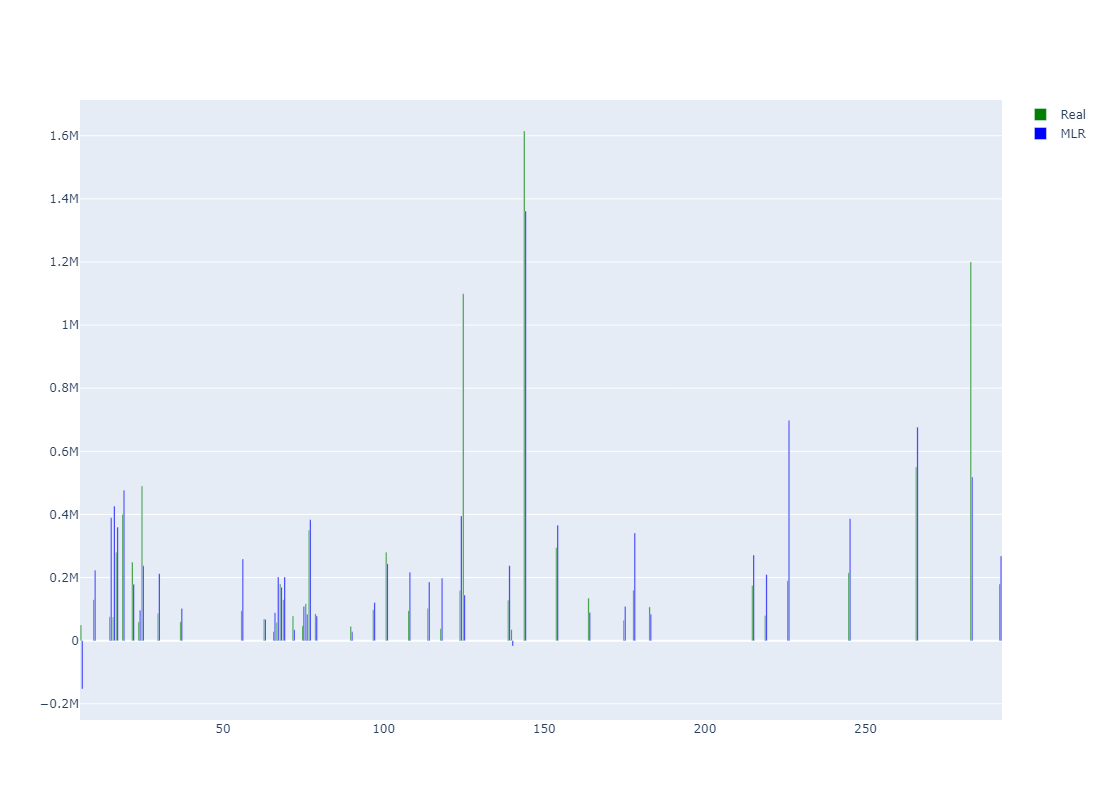

In [87]:
import plotly.graph_objects as go

# Grafico preço real e valor previsto
fig = go.Figure(
    data=[
        go.Bar(x=X_train_13.ID, y=y_test.Price_Real, name="Real", marker_color='green'),
        go.Bar(x=X_train_13.ID, y=y_test.Price_prev, name="MLR",  marker_color='blue'),
    ],
)
fig.update_layout(
    autosize=False,
    width=1000,
    height=800)

fig.show()